# 09 — Better generalisation: learning to write *any* figure

Notebook 08 showed that the DQN trained on 10 letters does not generalise: with only 10 targets, it memorises
10 behaviours. We test two ideas to make it learn the general rule *"draw the target segments that are still
missing, then press STOP"*:

1. **Diversity of the targets.** Train on **random stroke figures**: a new figure at every episode
   (`src/figures.py`). Figures identical to one of the 26 letters are rejected, so that **no letter is ever seen
   during training**: the 26 letters become a pure test set.
2. **A more helpful observation** (*rich* observation, 266 numbers instead of 170). We add:
   - the **missing segments** (target minus drawn, 72 bits): the STOP decision becomes "nothing is missing";
   - a **local view around the pen** (24 bits): for each of the 8 directions, is the segment in that direction
     *missing*, *already drawn*, or *outside the grid*? A local rule ("if a segment is missing next to me, draw it")
     can then be learned once and used at every position of the grid and for every letter.

To separate the effect of each idea, four configurations (2 × 2):

| | trained on the 10 letters | trained on random figures |
|---|---|---|
| **basic observation** (170) | notebooks 07–08 | **A** |
| **rich observation** (266) | **C** | **B** (2 seeds) |

All are tested on the **26 letters** (for A and B, none of them was seen during training; for C, 10 were seen and
16 not) and, for A and B, on 50 held-out random figures.

| Parameter | A and B | C |
|---|---|---|
| training steps | 1,000,000 | 300,000 (as notebook 07) |
| ε | 1 → 0.05 over the first 30 % of the steps | 1 → 0.05 over 60 % |
| memory | 200,000 transitions | 100,000 |
| other | same as notebook 07: γ = 0.99, Adam 0.0005, mini-batch 64 every 4 steps, target network every 1,000 steps | |

In [1]:
import sys
sys.path.insert(0, "..")

import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image

from src.letters import make_letter, TRAINING_LETTERS, TEST_LETTERS
from src.environment import LetterWritingEnv
from src.figures import random_figure
from src.dqn import train_dqn, QNetwork, greedy_episode, obs_size
from src.visualization import plot_letters, plot_episodes, animate_episodes, SURFACE, TEXT, MUTED

torch.set_num_threads(1)
GAMMA = 0.99
ALL_LETTERS = TRAINING_LETTERS + TEST_LETTERS
RETRAIN = False   # True: train again (about 20 min per A/B run, 5 min for C) even if saved networks exist

# (config, seed): rich observation?, trained on random figures?
RUNS = {("A", 0): (False, True), ("B", 0): (True, True), ("B", 1): (True, True), ("C", 0): (True, False)}
fig_rng = np.random.default_rng(12345)
held_out = [random_figure(fig_rng) for _ in range(50)]   # 50 random figures never used for training


def style(ax, title=None, xlabel=None, ylabel=None):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#ecebe7", lw=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    if title:
        ax.set_title(title, color=TEXT, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, fontsize=9)

## 1. What random figures look like

16 examples. Each training episode uses a new one (about 1,900 different shapes out of 2,000 draws).

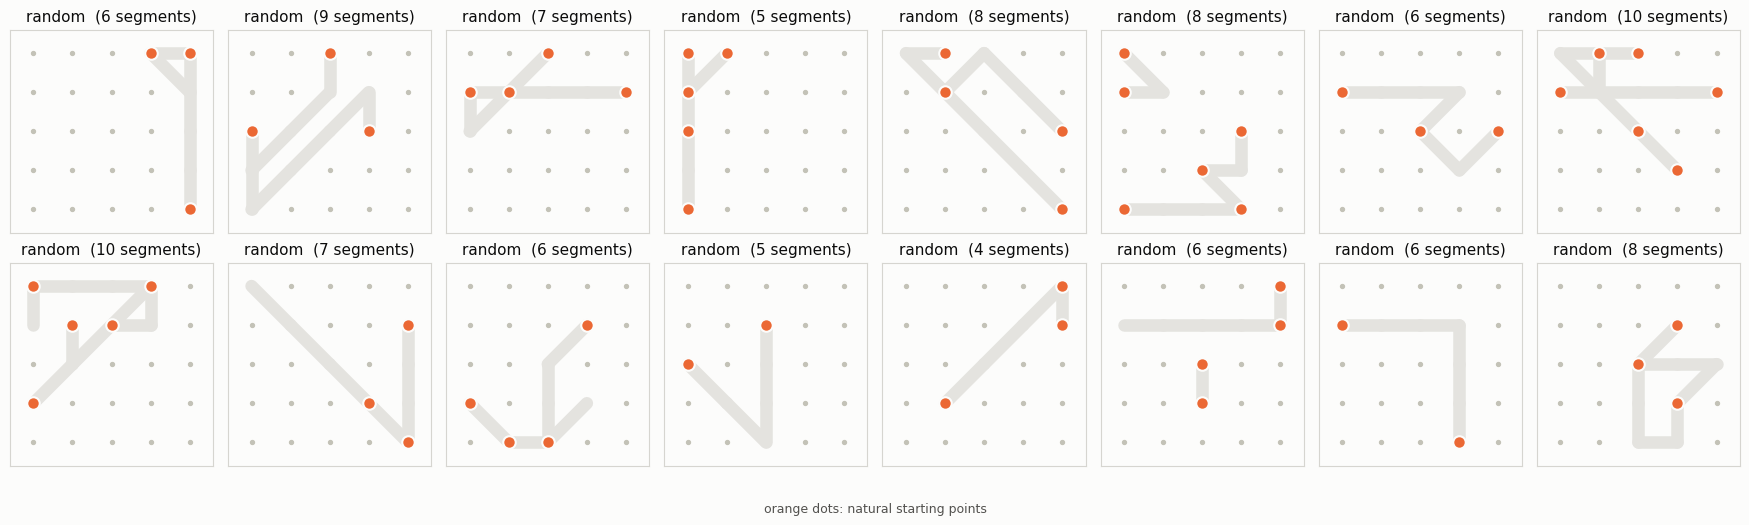

In [2]:
examples = [random_figure(np.random.default_rng(i)) for i in range(16)]
plot_letters(examples, ncols=8, path="../results/09_random_figures.png")
plt.show()

## 2. Training (or loading the saved networks)

The trained networks are saved in `results/09_dqn_*.pt` with their learning curves. If they are present (and
`RETRAIN = False`), they are loaded in a few seconds. Training everything again takes about 65 minutes.

In [3]:
def file_name(config, seed):
    return f"../results/09_dqn_{config}" + (f"_seed{seed}" if seed else "")

nets, curves = {}, {}
for (config, seed), (rich, random_targets) in RUNS.items():
    path = file_name(config, seed)
    if os.path.exists(path + ".pt") and os.path.exists(path + "_curves.npz") and not RETRAIN:
        print(f"{config} seed {seed}: loaded")
    else:
        print(f"--- training {config} seed {seed} ---")
        if random_targets:
            res = train_dqn(None, total_steps=1_000_000, rich_obs=rich, task_sampler=random_figure,
                            eval_letters=ALL_LETTERS, eval_figures=held_out, eval_every=50_000,
                            buffer_size=200_000, eps_fraction=0.3, seed=seed)
        else:
            res = train_dqn(TRAINING_LETTERS, total_steps=300_000, rich_obs=rich, eval_letters=ALL_LETTERS,
                            eval_figures=held_out, eval_every=10_000, seed=seed)
        torch.save(res["net"].state_dict(), path + ".pt")
        np.savez(path + "_curves.npz", eval_steps=res["eval_steps"],
                 letters_perfect_mean=np.array([np.mean([p for _, p in r.values()]) for r in res["eval_results"]]),
                 figures_perfect=np.array([np.mean([p for _, p in r.values()]) for r in res["eval_fig_results"]]),
                 time=res["time"])
    net = QNetwork(256, obs_size(rich))
    net.load_state_dict(torch.load(path + ".pt"))
    net.eval()
    nets[(config, seed)] = net
    curves[(config, seed)] = np.load(path + "_curves.npz")

# Reference: the networks of notebook 07 (basic observation, 10 letters)
for seed in [0, 1, 2]:
    net = QNetwork()
    net.load_state_dict(torch.load(f"../results/07_dqn_seed{seed}.pt"))
    net.eval()
    nets[("07", seed)] = net

A seed 0: loaded
B seed 0: loaded
B seed 1: loaded
C seed 0: loaded


## 3. Learning curves

Fraction of perfect drawings during training, on the 26 letters (left) and on the 50 held-out random figures
(right). For A and B the letters are never seen during training: the left curve measures generalisation.

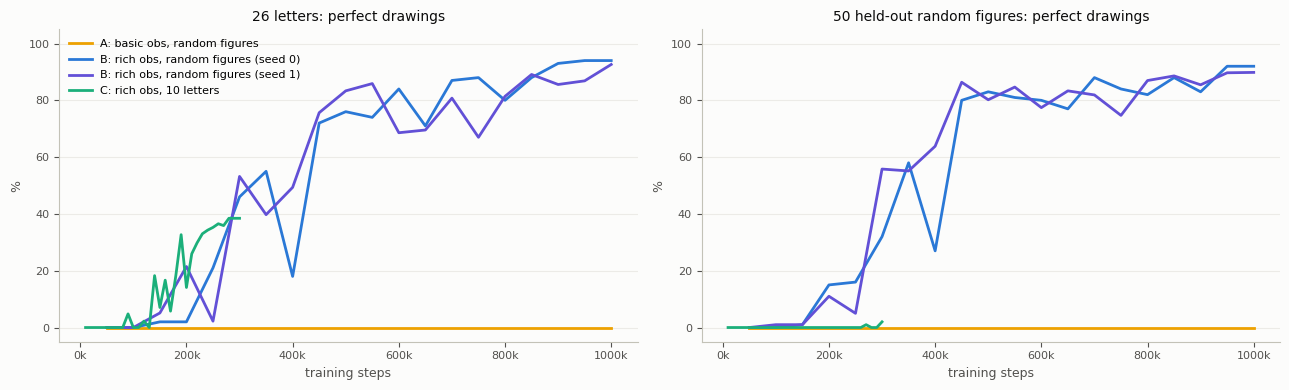

In [4]:
colors = {("A", 0): "#eda100", ("B", 0): "#2a78d6", ("B", 1): "#6250d6", ("C", 0): "#1baf7a"}
labels = {("A", 0): "A: basic obs, random figures", ("B", 0): "B: rich obs, random figures (seed 0)",
          ("B", 1): "B: rich obs, random figures (seed 1)", ("C", 0): "C: rich obs, 10 letters"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), facecolor=SURFACE)
for key, c in curves.items():
    axes[0].plot(c["eval_steps"], 100 * c["letters_perfect_mean"], color=colors[key], lw=2, label=labels[key])
    axes[1].plot(c["eval_steps"], 100 * c["figures_perfect"], color=colors[key], lw=2, label=labels[key])
style(axes[0], "26 letters: perfect drawings", "training steps", "%")
style(axes[1], "50 held-out random figures: perfect drawings", "training steps", "%")
for ax in axes:
    ax.set_ylim(-5, 105)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x / 1000)}k"))
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("../results/09_learning_curves.png", dpi=150, facecolor=SURFACE)
plt.show()

## 4. Final results on the 26 letters

Greedy policy from every natural starting point. *perfect* = complete, no segment outside, then STOP.

In [5]:
RICH = {key: rich for key, (rich, _) in RUNS.items()}

def results(key, names):
    rich = RICH.get(key, False)
    out = {}
    for name in names:
        env = LetterWritingEnv(name)
        eps = [greedy_episode(nets[key], env, s, GAMMA, rich) for s in env.letter.start_points]
        out[name] = {"perfect": np.mean([e["completed"] and e["off_letter"] == 0 for e in eps]),
                     "coverage": np.mean([e["drawn"] / env.k for e in eps]),
                     "stop": np.mean([e["history"][-1]["event"] == "stop" for e in eps])}
    return out

final = {key: results(key, ALL_LETTERS) for key in nets}

def summary(key, names, metric="perfect"):
    return np.mean([final[key][n][metric] for n in names])

rows = [("notebook 07 (basic, 10 letters)", [("07", s) for s in [0, 1, 2]]), ("A (basic, random figures)", [("A", 0)]),
        ("C (rich, 10 letters)", [("C", 0)]), ("B (rich, random figures)", [("B", 0), ("B", 1)])]
print(f"{'configuration':<34}{'10 first letters':>18}{'16 other letters':>18}{'STOP (16 others)':>18}")
for label, keys in rows:
    a = np.mean([summary(k, TRAINING_LETTERS) for k in keys])
    b = np.mean([summary(k, TEST_LETTERS) for k in keys])
    st = np.mean([summary(k, TEST_LETTERS, "stop") for k in keys])
    print(f"{label:<34}{a:>18.0%}{b:>18.0%}{st:>18.0%}")
print("(for A and B, none of the 26 letters was seen during training; for 07 and C, the 10 first letters were)")

print(f"\nperfect drawings per letter")
print(f"{'letter':<7}{'07':>7}{'A':>7}{'C':>7}{'B s0':>7}{'B s1':>7}")
for name in ALL_LETTERS:
    v07 = np.mean([final[("07", s)][name]["perfect"] for s in [0, 1, 2]])
    print(f"{name:<7}{v07:>7.0%}{final[('A', 0)][name]['perfect']:>7.0%}{final[('C', 0)][name]['perfect']:>7.0%}"
          f"{final[('B', 0)][name]['perfect']:>7.0%}{final[('B', 1)][name]['perfect']:>7.0%}")

configuration                       10 first letters  16 other letters  STOP (16 others)
notebook 07 (basic, 10 letters)                  96%                0%                0%
A (basic, random figures)                         0%                0%                0%
C (rich, 10 letters)                            100%                0%                0%
B (rich, random figures)                         94%               92%               92%
(for A and B, none of the 26 letters was seen during training; for 07 and C, the 10 first letters were)

perfect drawings per letter
letter      07      A      C   B s0   B s1
I         100%     0%   100%   100%    75%
L         100%     0%   100%   100%   100%
T         100%     0%   100%   100%    33%
E         100%     0%   100%   100%   100%
F          89%     0%   100%   100%   100%
H         100%     0%   100%   100%    75%
N         100%     0%   100%   100%   100%
Z         100%     0%   100%   100%   100%
V          67%     0%   100%   100%

## 5. The 26 letters drawn by network B (seed 0), which has never seen any of them

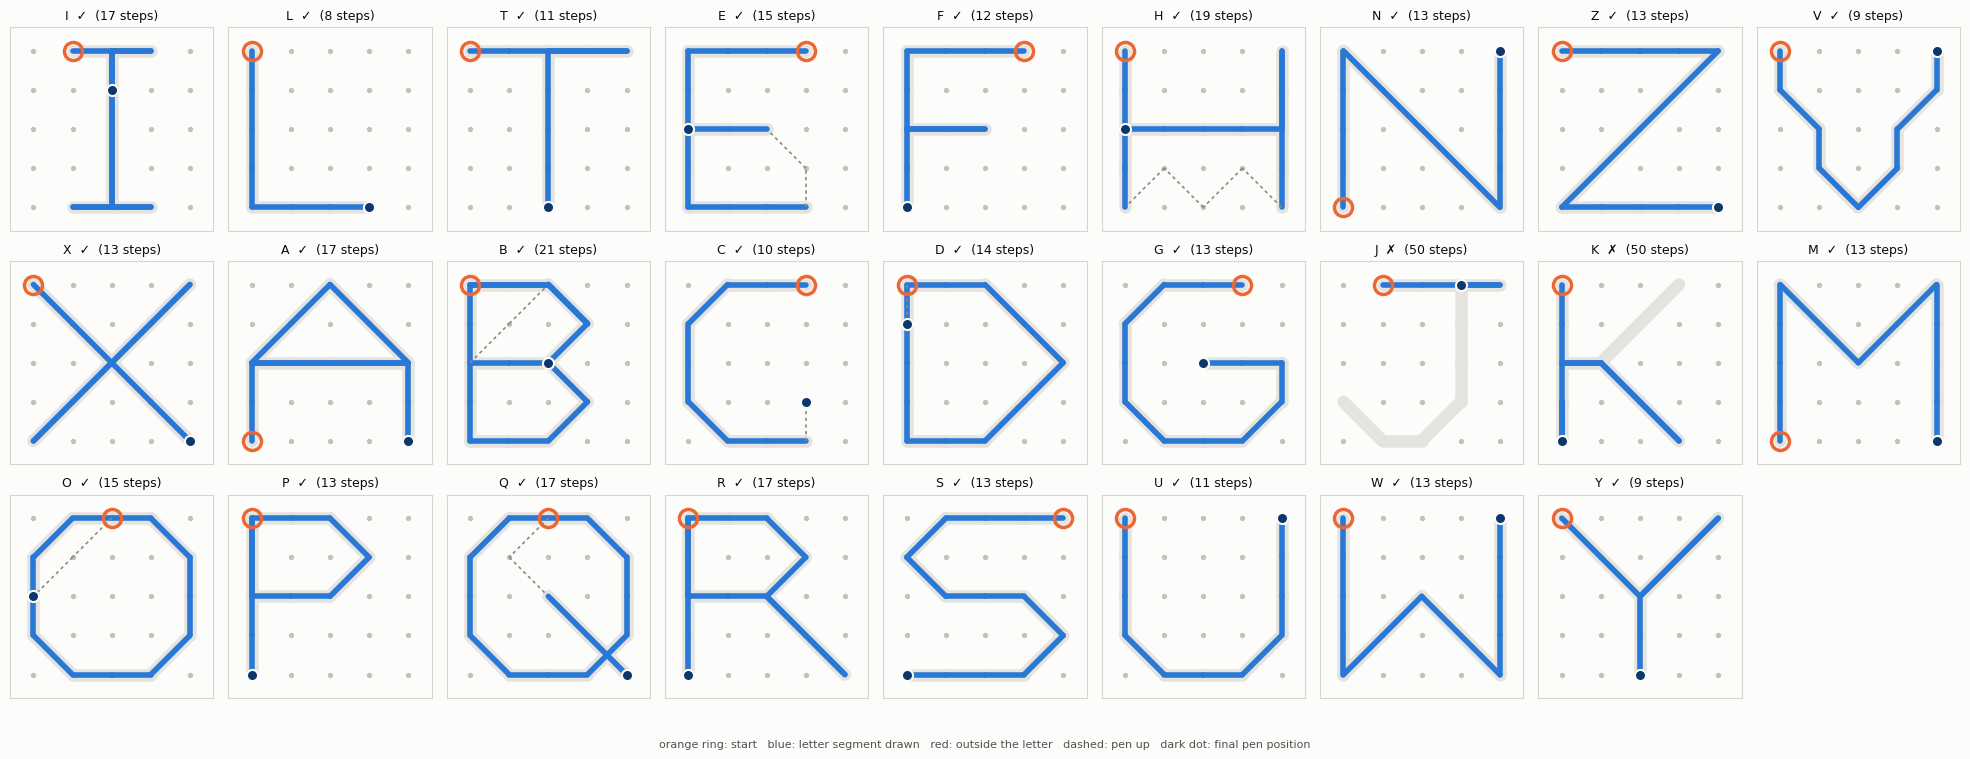

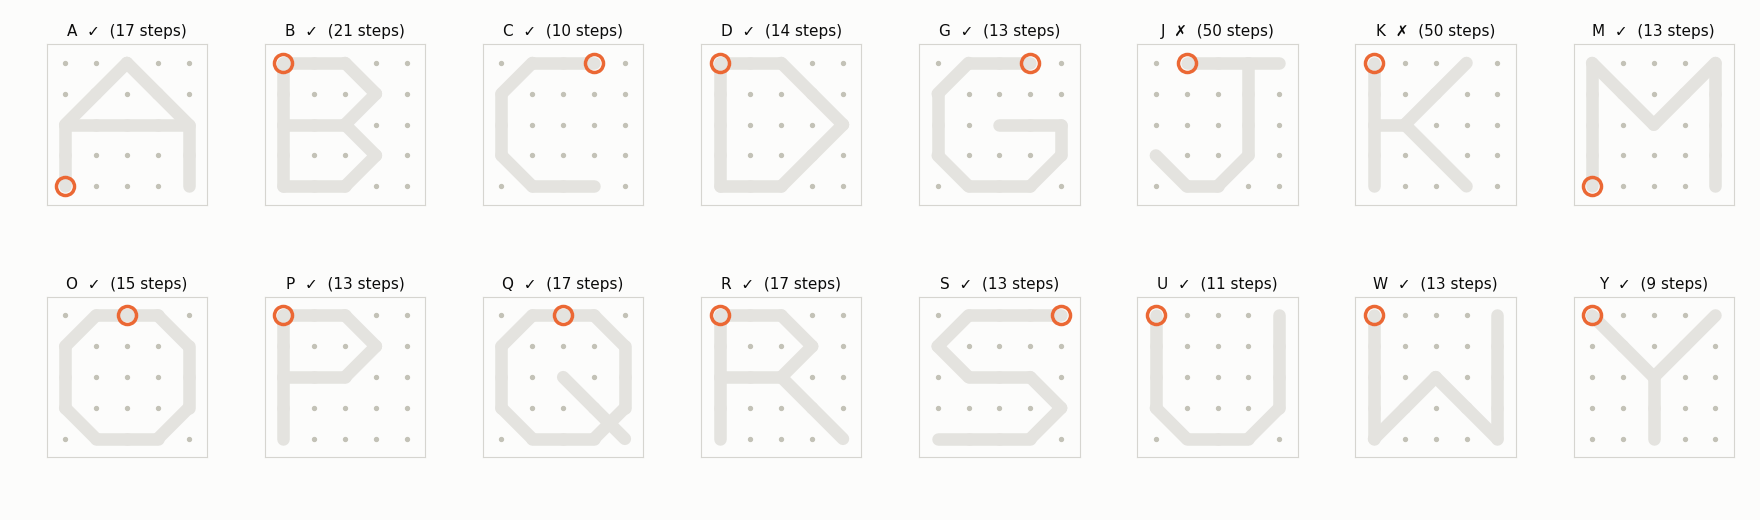

In [6]:
net_b = nets[("B", 0)]
panels = []
for name in ALL_LETTERS:
    env = LetterWritingEnv(name)
    ep = greedy_episode(net_b, env, env.letter.start_points[0], GAMMA, rich=True)
    ok = ep["completed"] and ep["off_letter"] == 0
    panels.append((env.letter, ep["history"], f"{name}  {'✓' if ok else '✗'}  ({ep['steps']} steps)"))
fig = plot_episodes(panels, ncols=9, path="../results/09_B_all_letters.png")
for ax in fig.axes:
    ax.title.set_fontsize(9)
plt.show()
animate_episodes(panels[10:], "../results/09_B_unseen_letters.gif", ncols=8)
Image(filename="../results/09_B_unseen_letters.gif")

## 6. Where does B still fail?

Every starting point where one of the two B networks does not draw the letter perfectly.

11 imperfect episodes


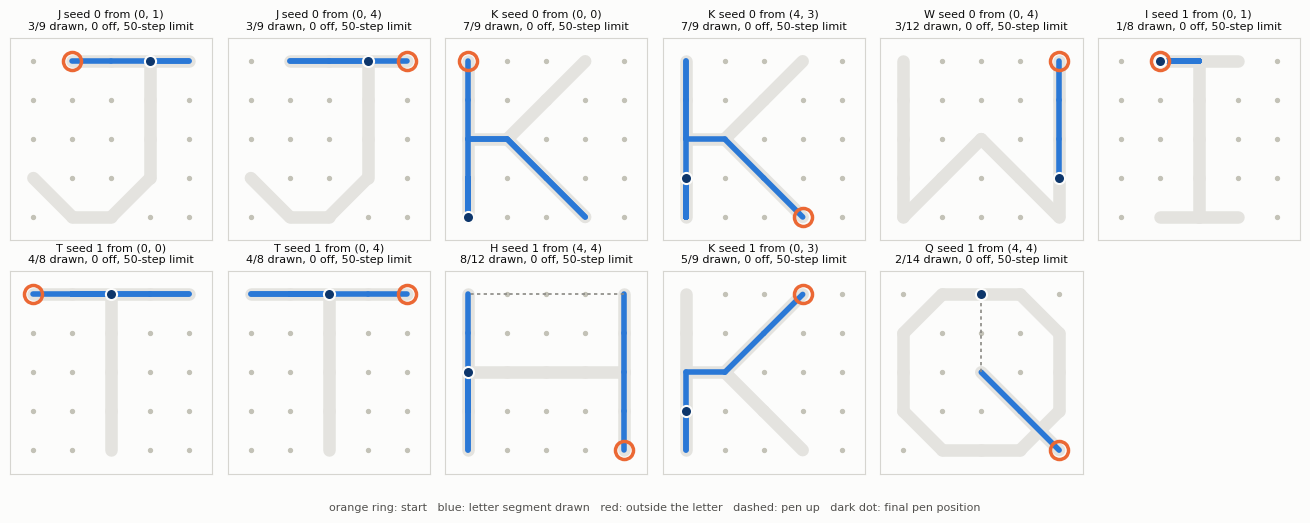

In [7]:
fails = []
for seed in [0, 1]:
    for name in ALL_LETTERS:
        env = LetterWritingEnv(name)
        for start in env.letter.start_points:
            ep = greedy_episode(nets[("B", seed)], env, start, GAMMA, rich=True)
            if not (ep["completed"] and ep["off_letter"] == 0):
                end = "STOP" if ep["history"][-1]["event"] == "stop" else "50-step limit"
                fails.append((env.letter, ep["history"], f"{name} seed {seed} from {start}\n{ep['drawn']}/{env.k} drawn, "
                              f"{ep['off_letter']} off, {end}"))
print(f"{len(fails)} imperfect episodes")
if fails:
    fig = plot_episodes(fails[:12], ncols=6, path="../results/09_B_failures.png")
    for ax in fig.axes:
        ax.title.set_fontsize(8)
    plt.show()

## What to notice

(The numbers below come from the saved networks; if you set `RETRAIN = True` your numbers will be close but
not identical.)

- **Only B generalises — and it generalises very well.** Trained on random figures with the rich observation,
  it draws **94 % of the 10 first letters and 92 % of the 16 other letters perfectly, and presses STOP correctly
  in 92 % of the cases — although it has never seen a single letter during training.** It also draws 90–92 % of
  the held-out random figures perfectly. The two seeds agree (93–94 % of all letter/starting-point pairs).
- **Diversity alone is not enough (A: 0 % everywhere).** With the basic observation, the network cannot even
  learn the random figures (0 % on the held-out figures). To apply the rule "draw a missing segment next to the
  pen", it would have to combine, for each of the 72 segments, the target bit, the drawn bit and the pen position:
  a complicated function to discover from scratch while the target changes at every episode. Memorising is no
  longer possible, and the general rule is too hard to find: it learns nothing in 1,000,000 steps.
- **A good observation alone is not enough either (C: 100 % on its 10 letters, 0 % on the 16 others).** With only
  10 targets, memorising them is still the easiest solution, even with the rich observation.
- **So generalisation needs both ingredients**: diverse training tasks *force* the network to learn the general
  rule (memorising becomes impossible), and a suitable representation makes this rule *learnable* (the local
  view gives directly "is a segment missing in this direction?"). This matches what is known about generalisation
  in reinforcement learning (Cobbe et al., 2019: diverse, procedurally generated training levels are needed).
- **Where B still fails** (11 imperfect episodes out of 140): every time, the agent draws part of the letter and
  then wanders until the 50-step limit, without pressing STOP. The failures happen at **junctions in the middle of
  a stroke** (J, K, T, H, I, W, Q): after finishing one stroke, the next one starts far from the pen, nothing is
  missing next to it, so the local view does not help and the agent must use the global "missing" bits to find
  its way. Possible improvements: longer training, a larger network, a local view at distance 2, or a
  convolutional network.
- **Cost**: about 20–35 minutes per B run (1,000,000 steps), against 4–7 minutes for the networks of notebook 07.

**For the debate — is the rich observation "cheating"?** It gives no information about the solution (no stroke
order, no starting point, no move): only what a person sees when writing — what remains to be drawn and what is
around the pen. Choosing the state representation is part of designing an RL agent, like choosing the reward
(notebooks 05–06). Our results show that this choice can decide everything: the same algorithm, with the same
data, goes from 0 % to 92 % on unseen letters.
